# 📝 Assignment: Which News Will Go Viral?
### Predicting News Popularity with Machine Learning

In the workshop you saw a complete Data Science pipeline. Now **you rebuild it yourself**, step by step, on the same data.

| | |
|---|---|
| **Dataset** | UCI – Online News Popularity (~39,644 Mashable articles, 58 features + `shares`) |
| **Tools** | Python, Pandas, Scikit-learn, Matplotlib/Seaborn, Google Colab |
| **Task** | Classify articles as **High** or **Low** popularity |
| **Time** | ~2–3 hours |

## What you will practice
EDA → Cleaning → Factor analysis → Train/Test split → Feature Selection → Random Forest → Evaluation → Logistic Regression → Model comparison → Predicting a new article

## Rules
- Write your own code in every cell marked `# YOUR CODE HERE`. Use the hints, the Pandas / scikit-learn documentation, and your notes from the workshop.
- Do **not** copy the workshop notebook cell by cell. Understanding is the goal.
- Use `RANDOM_STATE = 42` everywhere so that your results are comparable with your classmates'.
- Answer every **📝 Question** in the markdown cell right below it, in your own words (2–4 sentences).
- Run **Runtime → Restart and run all** before submitting, to make sure your notebook runs from top to bottom without errors.
- ✅/❌ **Checkpoint** cells are self-checks. They tell you if you are on the right track, but passing them is not the whole grade.

## Part 0 — Setup (provided)

In [27]:
import warnings, io, zipfile, urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

def check(condition, ok_msg, fail_msg):
    print(("✅ " + ok_msg) if condition else ("❌ " + fail_msg))

STUDENT_NAME = "Baraa Mousa"
print("Student:", STUDENT_NAME)

Student: Baraa Mousa


## Part 1 — Load the Data (10 pts)

The loading code is provided. Your job is to get to know the data.

In [28]:
URL = "https://archive.ics.uci.edu/static/public/332/online+news+popularity.zip"

try:
    raw = urllib.request.urlopen(URL, timeout=60).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        csv_name = [n for n in z.namelist() if n.endswith(".csv")][0]
        df = pd.read_csv(z.open(csv_name))
    print("Loaded from UCI ✅")
except Exception as e:
    # Fallback: upload OnlineNewsPopularity.csv (Colab: left sidebar > Files > Upload)
    print("Download failed:", e)
    df = pd.read_csv("OnlineNewsPopularity.csv")

Loaded from UCI ✅


**Task 1.1** The column names in this file have a hidden problem (look at `df.columns`, e.g. `' shares'`). Fix it, then display the first rows.

**Task 1.2** Print: the number of rows and columns, the number of missing values, and the number of duplicate rows. Also show `df.info()`.

**Task 1.3** Show summary statistics (`describe`) for `n_tokens_title`, `n_tokens_content`, `num_hrefs`, `num_imgs`, `num_videos`, `shares`.

> 💡 *Hint:* `df.columns.str.strip()`, `df.shape`, `df.isna().sum().sum()`, `df.duplicated().sum()`

In [29]:
df.columns = df.columns.str.strip()

display(df.head())

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [30]:
print("Number of rows and columns:", df.shape)

print("Missing values:", df.isna().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

df.info()

Number of rows and columns: (39644, 61)
Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 61 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   url                            39644 non-null  object 
 1   timedelta                      39644 non-null  float64
 2   n_tokens_title                 39644 non-null  float64
 3   n_tokens_content               39644 non-null  float64
 4   n_unique_tokens                39644 non-null  float64
 5   n_non_stop_words               39644 non-null  float64
 6   n_non_stop_unique_tokens       39644 non-null  float64
 7   num_hrefs                      39644 non-null  float64
 8   num_self_hrefs                 39644 non-null  float64
 9   num_imgs                       39644 non-null  float64
 10  num_videos                     39644 non-null  float64
 11  average_token_length          

In [31]:
columns = [
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos",
    "shares"
]

df[columns].describe()

,n_tokens_title,n_tokens_content,num_hrefs,num_imgs,num_videos,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,10.398749,546.514731,10.883690,4.544143,1.249874,3395.380184
std,2.114037,471.107508,11.332017,8.309434,4.107855,11626.950749
min,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,9.000000,246.000000,4.000000,1.000000,0.000000,946.000000
50%,10.000000,409.000000,8.000000,1.000000,0.000000,1400.000000
75%,12.000000,716.000000,14.000000,4.000000,1.000000,2800.000000
max,23.000000,8474.000000,304.000000,128.000000,91.000000,843300.000000


In [32]:
try:
    check("shares" in df.columns and not any(c != c.strip() for c in df.columns),
          "Column names are clean.", "Some column names still have spaces (e.g. ' shares').")
except NameError:
    print("❌ `df` is not defined yet.")

✅ Column names are clean.


**📝 Question 1.** What does one row of this dataset represent? Name three features you would *guess* are related to popularity, and why.

*Your answer:*

Each row represents one news article published on Mashable. I think the number of words in the content, the number of images, and the number of links may be related to popularity. These features may affect how interesting and informative the article is to readers.

## Part 2 — Explore the Target (10 pts)

**Task 2.1** Plot the distribution of `shares` in two panels side by side:
- left: raw `shares` (limit the x-axis to 0–20,000 so the plot is readable)
- right: `log10(shares)`

**Task 2.2** Print `df["shares"].describe()`.

> 💡 *Hint:* `sns.histplot`, `np.log10`, `plt.subplots(1, 2)`

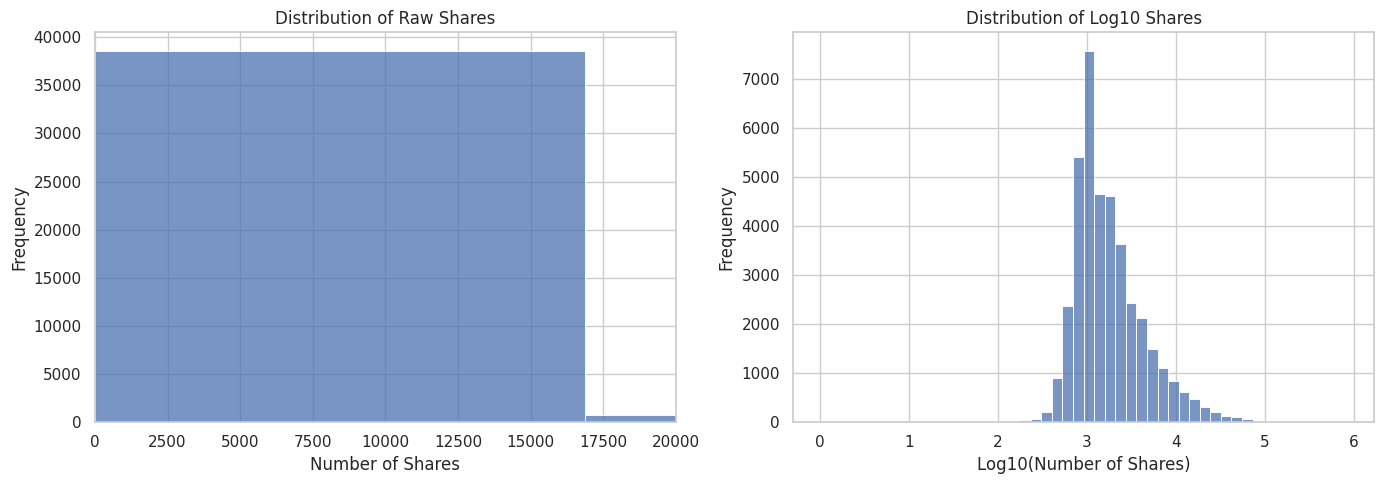

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Raw shares
sns.histplot(df["shares"], bins=50, ax=axes[0])

axes[0].set_xlim(0, 20000)
axes[0].set_title("Distribution of Raw Shares")
axes[0].set_xlabel("Number of Shares")
axes[0].set_ylabel("Frequency")

# Right plot: Log10 shares
sns.histplot(np.log10(df["shares"]), bins=50, ax=axes[1])

axes[1].set_title("Distribution of Log10 Shares")
axes[1].set_xlabel("Log10(Number of Shares)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [34]:
df["shares"].describe()

,shares
count,39644.000000
mean,3395.380184
std,11626.950749
min,1.000000
25%,946.000000
50%,1400.000000
75%,2800.000000
max,843300.000000


**📝 Question 2.** Describe the shape of the raw distribution. Why is the log scale more useful here? What does the gap between the mean and the median tell you?

*Your answer:*

The raw distribution is strongly right-skewed, meaning that most articles have a relatively low number of shares, while a few articles have very high shares. The log scale is more useful because it reduces the effect of extreme values and makes the distribution easier to understand. The mean being higher than the median indicates that a small number of highly shared articles increase the average.

## Part 3 — Cleaning & Defining the Target (15 pts)

**Task 3.1** Drop the columns `url` and `timedelta`.

**Task 3.2** Find and remove invalid rows:
- articles with **0 words** (`n_tokens_content == 0`)
- rows where `n_unique_tokens > 1` (a rate cannot exceed 1)

Print how many rows you removed and how many are left.

**Task 3.3** Create a new column `popular`: **1** if `shares` ≥ the **median** of `shares`, otherwise **0**. Print the class proportions.

> 💡 *Hint:* `df.drop(columns=[...])`, boolean filtering with `&`, `df["shares"].median()`, `.astype(int)`, `value_counts(normalize=True)`

In [35]:
df = df.drop(columns=["url", "timedelta"])

In [36]:
before = len(df)

df = df[
    (df["n_tokens_content"] > 0) &
    (df["n_unique_tokens"] <= 1)
].copy()

after = len(df)

removed = before - after

print("Rows removed:", removed)
print("Rows remaining:", after)

Rows removed: 1182
Rows remaining: 38462


In [37]:
median_shares = df["shares"].median()

df["popular"] = (
    df["shares"] >= median_shares
).astype(int)

print("Median shares:", median_shares)

print("\nClass proportions:")
print(df["popular"].value_counts(normalize=True))

Median shares: 1400.0

Class proportions:
popular
1    0.532032
0    0.467968
Name: proportion, dtype: float64


In [38]:
try:
    check("url" not in df.columns and "timedelta" not in df.columns,
          "`url` and `timedelta` were dropped.", "`url` / `timedelta` are still in the DataFrame.")
    check((df["n_tokens_content"] > 0).all() and (df["n_unique_tokens"] <= 1).all(),
          "No invalid rows remain.", "There are still articles with 0 words or n_unique_tokens > 1.")
    check("popular" in df.columns and 0.45 <= df["popular"].mean() <= 0.55,
          "Target `popular` exists and the classes are roughly balanced.",
          "`popular` is missing or the classes are not ~50/50. Did you use the median?")
except NameError:
    print("❌ `df` is not defined yet.")
except KeyError as e:
    print("❌ Missing column:", e)

✅ `url` and `timedelta` were dropped.
✅ No invalid rows remain.
✅ Target `popular` exists and the classes are roughly balanced.


**📝 Question 3.** (a) Why did we choose the **median** as the threshold? What would change if we used the top 10% of shares instead?
(b) Why do we drop `timedelta`, and why is `url` not useful as a feature?

*Your answer:*

We chose the median because it is less affected by extreme values and divides the articles into two approximately balanced groups. If we used the top 10%, only 10% of articles would be classified as popular, making the classes highly imbalanced. We drop timedelta because it is not needed for our prediction task. The URL is not useful because each article has a different link and it does not provide meaningful information about popularity.

## Part 4 — What Influences Popularity? (20 pts)

**Task 4.1 — Correlation.** Compute the correlation of every feature (excluding `shares` and `popular`) with `popular`. Plot the **8 most negative and the 8 most positive** as a horizontal bar chart (green = positive, red = negative).

**Task 4.2 — Channel.** The `data_channel_is_*` columns are one-hot flags. For each channel, compute the **share of popular articles** and plot it as a sorted horizontal bar chart, with a vertical line at 0.5.

**Task 4.3 — Weekday.** Do the same for the `weekday_is_*` columns (a bar chart, one bar per day).

**Task 4.4 — Images, videos and links.** For `num_imgs`, `num_videos` and `num_hrefs`, group each into buckets (e.g. 0, 1–2, 3–5, 6–10, 10+) and plot the share of popular articles per bucket (three small bar charts side by side).

> 💡 *Hints:* `df[features].corrwith(df["popular"])`, `.sort_values()`, `pd.concat([s.head(8), s.tail(8)])`; for flags: `df[df[col] == 1]["popular"].mean()`; for buckets: `pd.cut(...)` then `groupby(...).mean()`

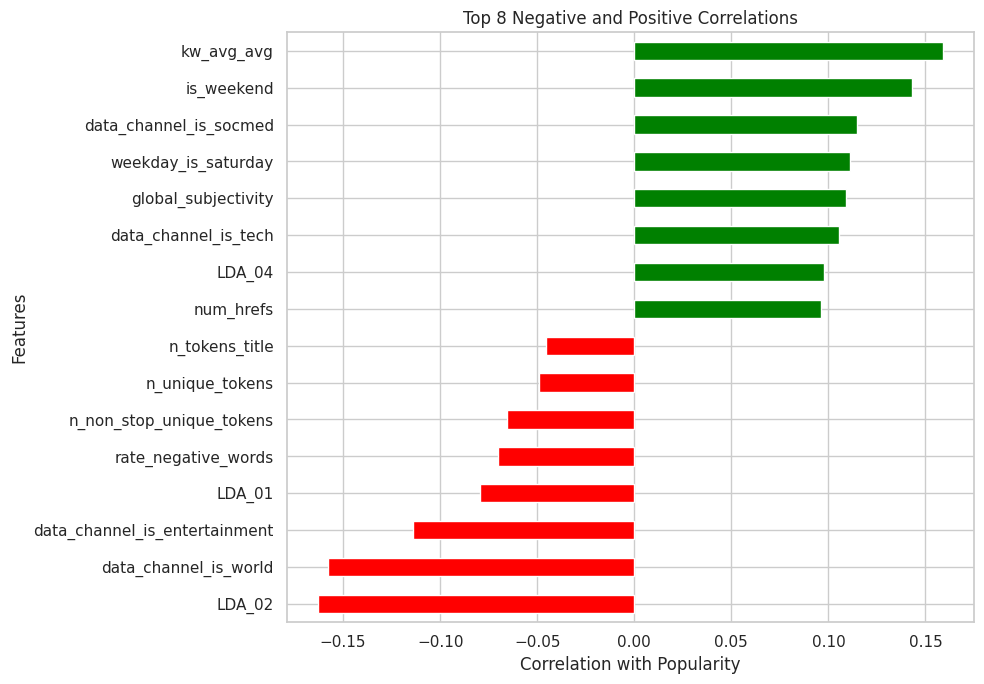

In [39]:
features = [
    col for col in df.columns
    if col not in ["shares", "popular"]
]

correlations = df[features].corrwith(df["popular"])

top_corr = pd.concat([
    correlations.sort_values().head(8),
    correlations.sort_values().tail(8)
])

colors = [
    "green" if value > 0 else "red"
    for value in top_corr.values
]

plt.figure(figsize=(10, 7))

top_corr.plot(
    kind="barh",
    color=colors
)

plt.title("Top 8 Negative and Positive Correlations")
plt.xlabel("Correlation with Popularity")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

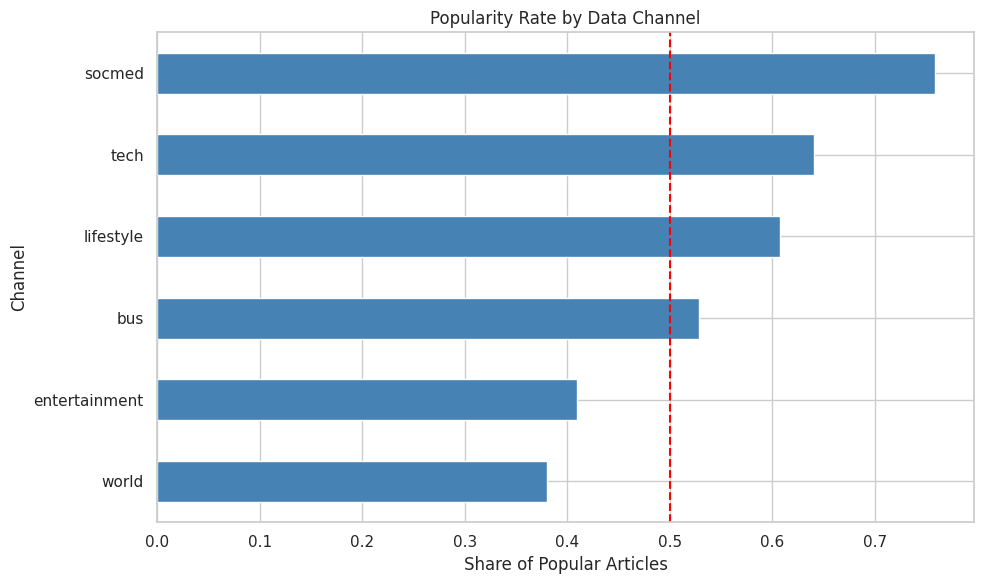

In [40]:
channel_cols = [
    col for col in df.columns
    if col.startswith("data_channel_is_")
]

channel_popularity = pd.Series({
    col.replace("data_channel_is_", ""):
    df.loc[df[col] == 1, "popular"].mean()
    for col in channel_cols
})

channel_popularity = channel_popularity.sort_values()

plt.figure(figsize=(10, 6))

channel_popularity.plot(
    kind="barh",
    color="steelblue"
)

plt.axvline(0.5, color="red", linestyle="--")

plt.title("Popularity Rate by Data Channel")
plt.xlabel("Share of Popular Articles")
plt.ylabel("Channel")

plt.tight_layout()
plt.show()

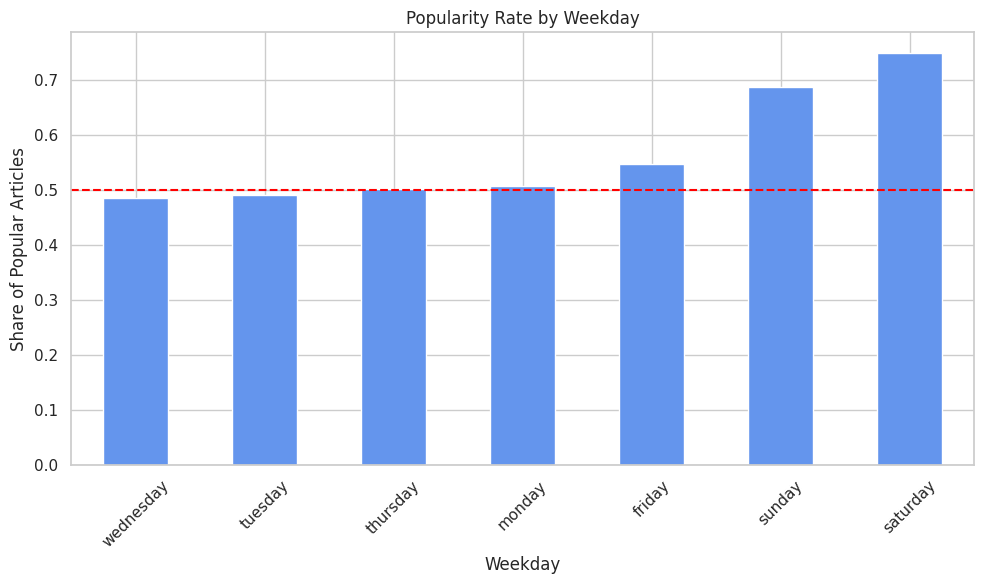

In [41]:
weekday_cols = [
    col for col in df.columns
    if col.startswith("weekday_is_")
]

weekday_popularity = pd.Series({
    col.replace("weekday_is_", ""):
    df.loc[df[col] == 1, "popular"].mean()
    for col in weekday_cols
})

weekday_popularity = weekday_popularity.sort_values()

plt.figure(figsize=(10, 6))

weekday_popularity.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.axhline(0.5, color="red", linestyle="--")

plt.title("Popularity Rate by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Share of Popular Articles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

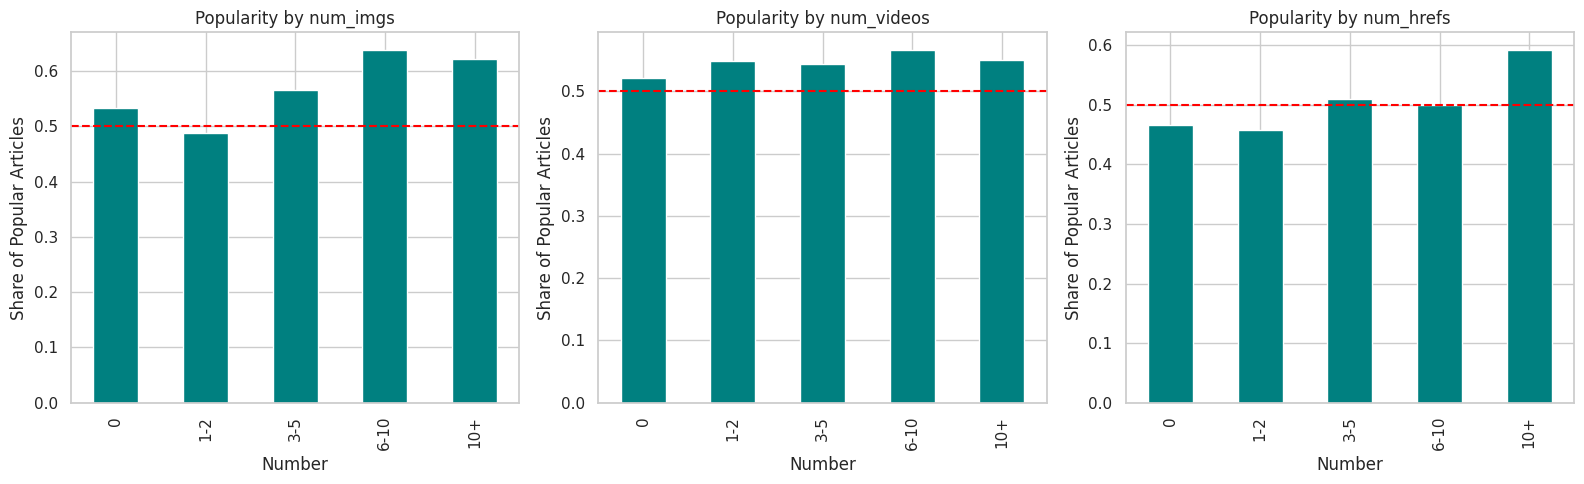

In [42]:
columns = ["num_imgs", "num_videos", "num_hrefs"]

bins = [-1, 0, 2, 5, 10, np.inf]

labels = ["0", "1-2", "3-5", "6-10", "10+"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(columns, axes):

    df["bucket"] = pd.cut(
        df[col],
        bins=bins,
        labels=labels
    )

    popularity_rate = (
        df.groupby("bucket", observed=False)["popular"]
        .mean()
    )

    popularity_rate.plot(
        kind="bar",
        ax=ax,
        color="teal"
    )

    ax.set_title(f"Popularity by {col}")
    ax.set_xlabel("Number")
    ax.set_ylabel("Share of Popular Articles")

    ax.axhline(0.5, color="red", linestyle="--")

plt.tight_layout()
plt.show()

df.drop(columns=["bucket"], inplace=True)

**📝 Question 4.** Summarize your **three most interesting findings** from this part. Then explain: why can we not conclude that adding more images *causes* an article to be more popular?

*Your answer:*

The analysis shows that some article features have a stronger relationship with popularity than others. Popularity rates also differ between data channels and publishing weekdays. The number of images, videos, and links may be associated with popularity, but this does not prove causation. Other factors, such as article topic and writing quality, may also influence popularity.

## Part 5 — Train / Test Split (5 pts)

**Task 5.1** Define a list `features_all` containing every column except `shares` and `popular`.

**Task 5.2** Create `X` (the features) and `y` (the `popular` column), then split into `X_train, X_test, y_train, y_test` with:
- 80% train / 20% test
- **stratified** on `y`
- `random_state=RANDOM_STATE`

Print the shapes.

In [43]:
features_all = [
    col for col in df.columns
    if col not in ["shares", "popular"]
]

In [44]:
X = df[features_all]

y = df["popular"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (30769, 58)
X_test shape: (7693, 58)
y_train shape: (30769,)
y_test shape: (7693,)


In [45]:
try:
    ratio = len(X_test) / (len(X_train) + len(X_test))
    check(abs(ratio - 0.2) < 0.01, "Split is about 80/20.", f"Test ratio is {ratio:.2f}, expected 0.20.")
    check("shares" not in X_train.columns and "popular" not in X_train.columns,
          "Target and `shares` are not in the features.",
          "`shares` or `popular` is still in X: that would be data leakage!")
    check(abs(y_train.mean() - y_test.mean()) < 0.01, "Split is stratified.", "Class balance differs between train and test: did you use stratify=y?")
except NameError as e:
    print("❌ Not defined yet:", e)

✅ Split is about 80/20.
✅ Target and `shares` are not in the features.
✅ Split is stratified.


**📝 Question 5.** Why must we split the data **before** doing feature selection? What is *data leakage*, and how could it make our results look better than they really are?

*Your answer:*

We must split the data before feature selection to make sure that the test data does not influence the training process. Data leakage happens when information from the test set is used during training. This can make the model appear more accurate than it really is because it has indirectly learned from the test data.

## Part 6 — Feature Selection (10 pts)

**Task 6.1** Compute the **Mutual Information** between every feature and the target, using **only the training set** (`mutual_info_classif`, `random_state=RANDOM_STATE`). Store it as a Series sorted from highest to lowest.

**Task 6.2** Plot the top 20 features.

**Task 6.3** Keep the **top K = 25** features. Create a list `selected`, and the reduced matrices `X_train_sel` and `X_test_sel`.

> 💡 *Hint:* wrap the output in `pd.Series(..., index=X_train.columns)`

In [46]:
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=RANDOM_STATE
)

mi = pd.Series(
    mi_scores,
    index=X_train.columns
).sort_values(ascending=False)

print(mi)

LDA_02                           0.035401
kw_max_avg                       0.032932
LDA_04                           0.028587
LDA_00                           0.027778
kw_avg_avg                       0.025023
LDA_01                           0.024131
self_reference_max_shares        0.023249
LDA_03                           0.022904
kw_max_min                       0.021579
self_reference_min_shares        0.021279
self_reference_avg_sharess       0.020739
kw_min_avg                       0.019662
data_channel_is_world            0.015980
kw_avg_max                       0.013841
weekday_is_saturday              0.013671
kw_min_max                       0.012790
kw_avg_min                       0.010331
num_imgs                         0.009991
title_sentiment_polarity         0.009359
num_hrefs                        0.009324
global_sentiment_polarity        0.007330
weekday_is_monday                0.006966
is_weekend                       0.006701
data_channel_is_tech             0

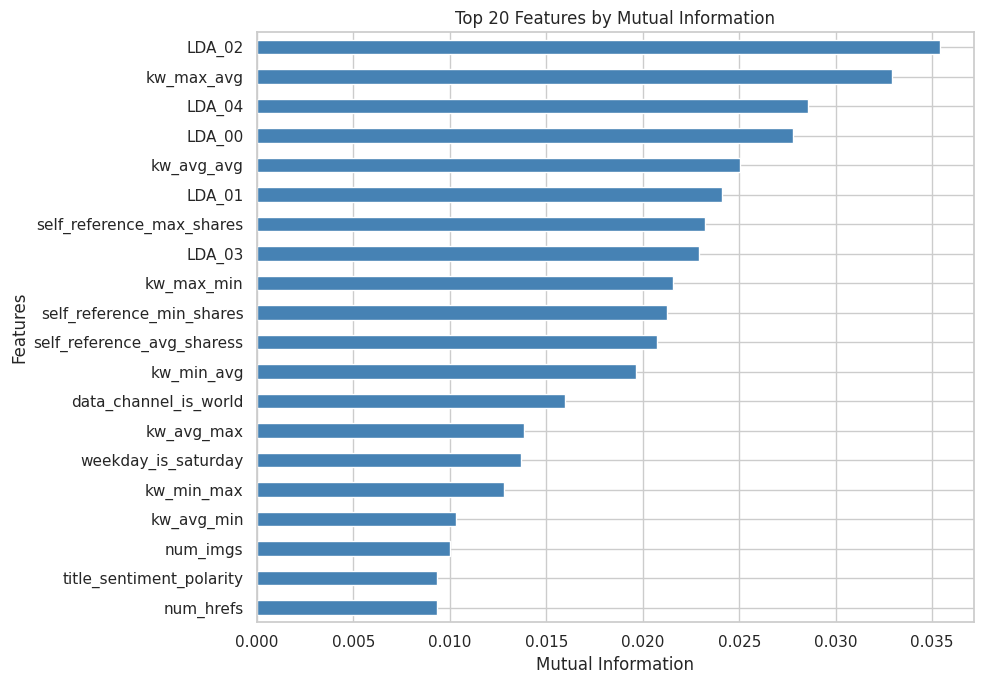

In [47]:
plt.figure(figsize=(10, 7))

mi.head(20).sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 20 Features by Mutual Information")
plt.xlabel("Mutual Information")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [48]:
K = 25

selected = mi.head(K).index.tolist()

X_train_sel = X_train[selected]

X_test_sel = X_test[selected]

print("Selected features:")
print(selected)

print("Training shape:", X_train_sel.shape)
print("Testing shape:", X_test_sel.shape)

Selected features:
['LDA_02', 'kw_max_avg', 'LDA_04', 'LDA_00', 'kw_avg_avg', 'LDA_01', 'self_reference_max_shares', 'LDA_03', 'kw_max_min', 'self_reference_min_shares', 'self_reference_avg_sharess', 'kw_min_avg', 'data_channel_is_world', 'kw_avg_max', 'weekday_is_saturday', 'kw_min_max', 'kw_avg_min', 'num_imgs', 'title_sentiment_polarity', 'num_hrefs', 'global_sentiment_polarity', 'weekday_is_monday', 'is_weekend', 'data_channel_is_tech', 'avg_positive_polarity']
Training shape: (30769, 25)
Testing shape: (7693, 25)


In [49]:
print(mi.head(5))

LDA_02        0.035401
kw_max_avg    0.032932
LDA_04        0.028587
LDA_00        0.027778
kw_avg_avg    0.025023
dtype: float64


In [50]:
try:
    check(len(selected) == 25 and X_train_sel.shape[1] == 25 and X_test_sel.shape[1] == 25,
          "25 features selected for both train and test.", "You should have exactly 25 selected features in X_train_sel and X_test_sel.")
    check(list(X_train_sel.columns) == list(X_test_sel.columns), "Train/test columns match.", "Train and test columns differ.")
except NameError as e:
    print("❌ Not defined yet:", e)

✅ 25 features selected for both train and test.
✅ Train/test columns match.


**📝 Question 6.** In your own words, what does Mutual Information measure, and how is it different from correlation? List the top 5 features you found. Do they match your expectations from Part 4?

*Your answer:*

Mutual Information measures how much information a feature provides about the target variable. Unlike correlation, it can detect both linear and non-linear relationships.

The top five features are LDA_02 (0.035401), kw_max_avg (0.032932), LDA_04 (0.028587), LDA_00 (0.027778), and kw_avg_avg (0.025023).

These results suggest that article topics and keyword information are useful for predicting popularity. The results can be compared with Part 4 to check whether they match the correlation analysis.

## Part 7 — Baseline and Random Forest (10 pts)

**Task 7.1 — Baseline.** Train a `DummyClassifier(strategy="most_frequent")` and print its test accuracy.

**Task 7.2 — Random Forest.** Train a `RandomForestClassifier` on the selected features with these settings:

| parameter | value |
|---|---|
| `n_estimators` | 300 |
| `max_depth` | 15 |
| `min_samples_leaf` | 5 |
| `n_jobs` | -1 |
| `random_state` | `RANDOM_STATE` |

Store the model as `rf`.

In [51]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train_sel, y_train)

baseline_pred = baseline.predict(X_test_sel)

baseline_acc = accuracy_score(
    y_test,
    baseline_pred
)

print("Baseline Accuracy:", baseline_acc)

Baseline Accuracy: 0.5320421162095411


In [52]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf.fit(X_train_sel, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


**📝 Question 7.** Why do we always train a baseline first? How would you explain a Random Forest to a friend who has never heard of Machine Learning?

*Your answer:*

We train a baseline first to have a simple reference for comparing the performance of other models. Random Forest is a machine learning algorithm that combines many decision trees. Each tree makes a prediction, and the model combines their results to make the final decision. This usually gives better predictions than using a single decision tree.

## Part 8 — Evaluate the Random Forest (10 pts)

**Task 8.1** Predict on the test set. Store the predicted labels in `y_pred` and the **probability of the High class** in `y_proba`.

**Task 8.2** Print accuracy, ROC AUC, and the classification report (use the names `Low` and `High`).

**Task 8.3** Plot the **confusion matrix** and the **ROC curve** side by side.

**Task 8.4** Plot the **top 15 feature importances** from the forest.

> 💡 *Hint:* `rf.predict_proba(X_test_sel)[:, 1]`, `rf.feature_importances_`

In [62]:
y_pred = rf.predict(X_test_sel)

y_proba = rf.predict_proba(X_test_sel)[:, 1]

In [63]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("ROC AUC:", roc_auc_score(y_test, y_proba))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Low", "High"]
    )
)

Accuracy: 0.6663200311971923
ROC AUC: 0.7286159296359638

Classification Report:
              precision    recall  f1-score   support

         Low       0.66      0.59      0.62      3600
        High       0.67      0.73      0.70      4093

    accuracy                           0.67      7693
   macro avg       0.67      0.66      0.66      7693
weighted avg       0.67      0.67      0.66      7693



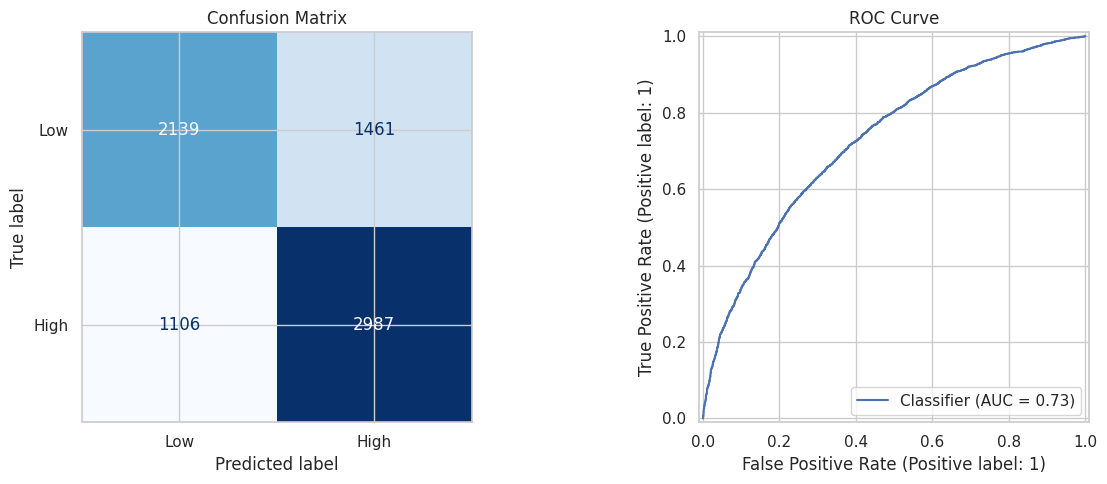

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "High"]
)

disp.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Confusion Matrix")

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    ax=axes[1]
)

axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()

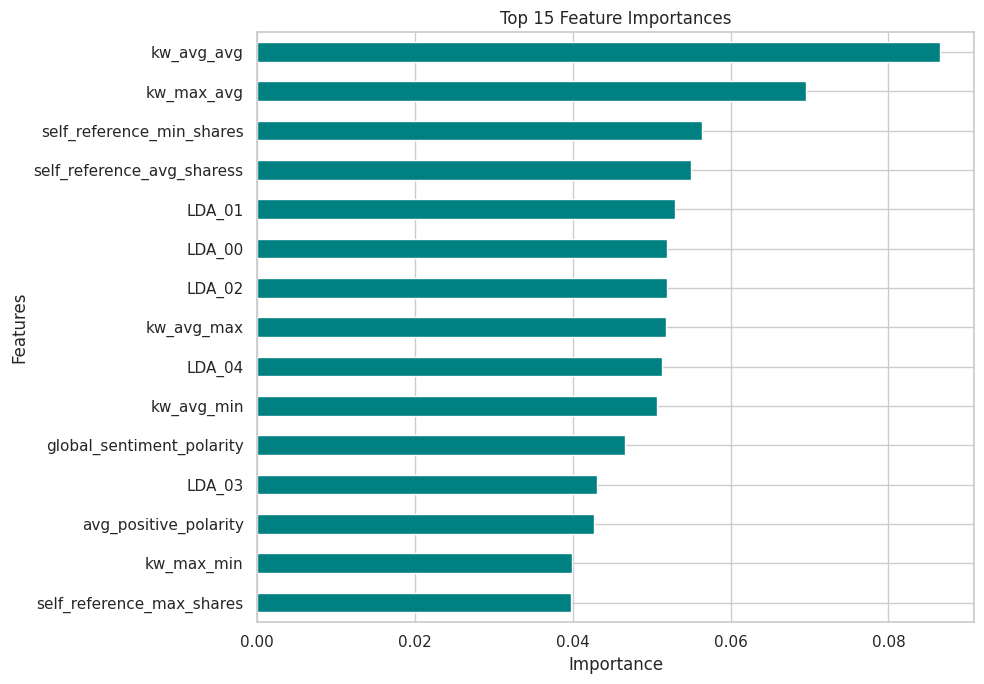

In [65]:
importance = pd.Series(
    rf.feature_importances_,
    index=X_train_sel.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 7))

importance.head(15).sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [66]:
try:
    acc = accuracy_score(y_test, y_pred)
    print(f"Your Random Forest accuracy: {acc:.3f}")
    check(acc > 0.55, "Accuracy is above the ~50% baseline.", "Accuracy is not clearly above the baseline. Check your steps.")
    check(0.55 <= acc <= 0.75, "Accuracy is in a plausible range (about 0.60 – 0.70 is typical for this dataset).",
          "Accuracy looks unusual for this dataset. Double-check for leakage or mistakes.")
except NameError as e:
    print("❌ Not defined yet:", e)

Your Random Forest accuracy: 0.666
✅ Accuracy is above the ~50% baseline.
✅ Accuracy is in a plausible range (about 0.60 – 0.70 is typical for this dataset).


**📝 Question 8.** (a) Explain the four cells of your confusion matrix in plain language (what does each count mean for this problem?).
(b) Why is accuracy only around 65% even though the model is "good"? What information is missing from the data?
(c) Are the most important features the same as in Part 6? Does *important* mean *causes popularity*?

*Your answer:*

1. The confusion matrix shows four results: True Positive means the model correctly predicted a popular article, while True Negative means it correctly predicted a non-popular article. False Positive means the model predicted an article as popular when it was not, and False Negative means it predicted a popular article as non-popular.

2. An accuracy of around 65% is reasonable because news popularity depends on many factors, such as audience interests, social media trends, and article quality, which are not included in the dataset.

3. The most important features may be different from Part 6 because each method measures importance differently. Important features help the model make predictions, but this does not mean they directly cause popularity.

## Part 9 — Logistic Regression & Model Comparison (15 pts)

**Task 9.1** Build a `Pipeline` (use `make_pipeline`) with a `StandardScaler` followed by `LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)`. Train it on the selected features and store it as `logreg`.

**Task 9.2** Evaluate it the same way as in Part 8: accuracy, ROC AUC, classification report, confusion matrix. Store `lr_pred` and `lr_proba`.

**Task 9.3** Plot the **ROC curves of both models on the same axes**.

**Task 9.4** Build a **comparison table** (a DataFrame) with one row per model — Baseline, Logistic Regression, Random Forest — and columns: Accuracy, Precision (High), Recall (High), F1 (High), ROC AUC.

**Task 9.5** Show the **top / bottom 8 coefficients** of the logistic regression as a bar chart, and print the **odds ratios** (`np.exp(coef)`) of the top 10.

> 💡 *Hints:* the final step of a pipeline is `logreg[-1]`, its coefficients are `logreg[-1].coef_[0]`. For the baseline's AUC you can use a constant probability of 0.5.

In [67]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
)

logreg.fit(X_train_sel, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42))])

Accuracy: 0.6414922656960873
ROC AUC: 0.693854955615278

Classification Report:
              precision    recall  f1-score   support

         Low       0.62      0.59      0.60      3600
        High       0.65      0.69      0.67      4093

    accuracy                           0.64      7693
   macro avg       0.64      0.64      0.64      7693
weighted avg       0.64      0.64      0.64      7693



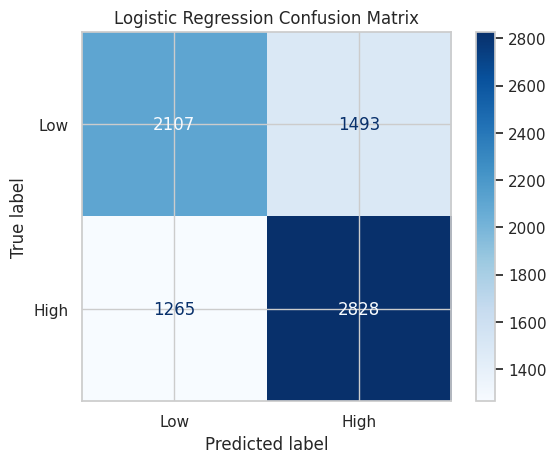

In [68]:
lr_pred = logreg.predict(X_test_sel)

lr_proba = logreg.predict_proba(X_test_sel)[:, 1]

print("Accuracy:", accuracy_score(y_test, lr_pred))

print("ROC AUC:", roc_auc_score(y_test, lr_proba))

print("\nClassification Report:")

print(classification_report(
    y_test,
    lr_pred,
    target_names=["Low", "High"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    display_labels=["Low", "High"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

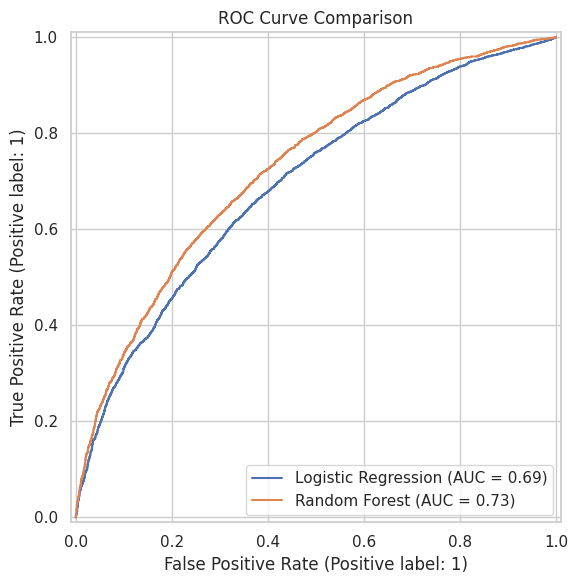

In [69]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_proba,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    name="Random Forest",
    ax=ax
)

ax.set_title("ROC Curve Comparison")

plt.tight_layout()
plt.show()

In [70]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, y_pred)
    ],

    "Precision (High)": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],

    "Recall (High)": [
        recall_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],

    "F1 (High)": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],

    "ROC AUC": [
        0.5,
        roc_auc_score(y_test, lr_proba),
        roc_auc_score(y_test, y_proba)
    ]
})

comparison = comparison.set_index("Model")

display(comparison.round(3))

,Accuracy,Precision (High),Recall (High),F1 (High),ROC AUC
Model,,,,,
Baseline,0.532,0.532,1.000,0.695,0.500
Logistic Regression,0.641,0.654,0.691,0.672,0.694
Random Forest,0.666,0.672,0.730,0.699,0.729


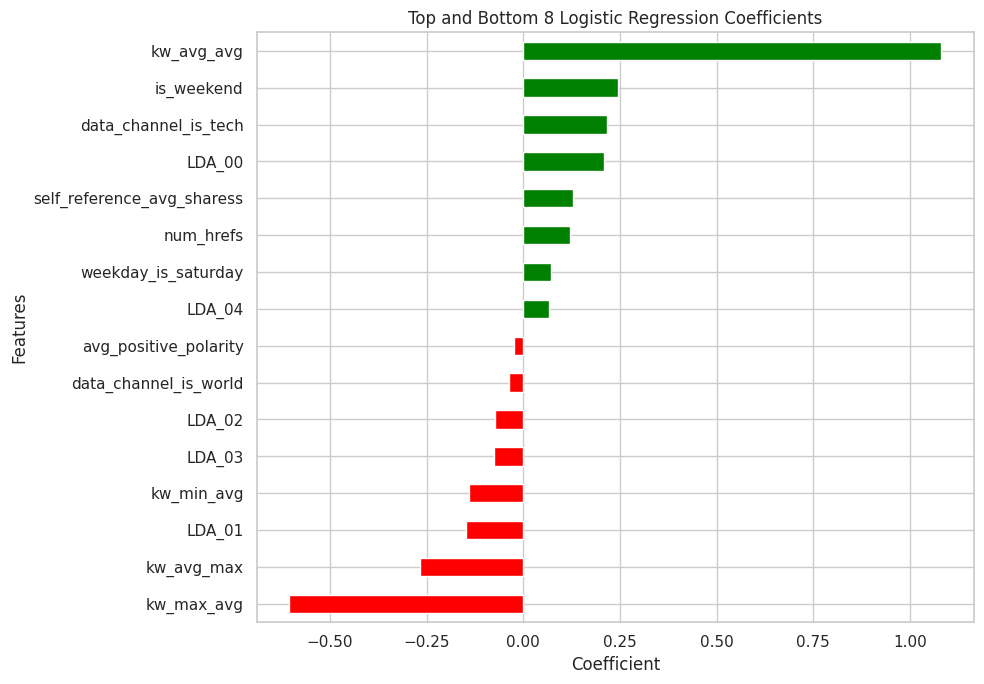

In [71]:
coef = pd.Series(
    logreg[-1].coef_[0],
    index=X_train_sel.columns
)

top_bottom = pd.concat([
    coef.sort_values().head(8),
    coef.sort_values().tail(8)
])

plt.figure(figsize=(10, 7))

top_bottom.plot(
    kind="barh",
    color=[
        "red" if value < 0 else "green"
        for value in top_bottom.values
    ]
)

plt.title("Top and Bottom 8 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [72]:
odds_ratios = np.exp(coef)

top_10_odds = odds_ratios.sort_values(
    ascending=False
).head(10)

print("Top 10 Odds Ratios:")
print(top_10_odds)

Top 10 Odds Ratios:
kw_avg_avg                    2.949396
is_weekend                    1.278650
data_channel_is_tech          1.240092
LDA_00                        1.233115
self_reference_avg_sharess    1.136715
num_hrefs                     1.128212
weekday_is_saturday           1.074755
LDA_04                        1.067556
title_sentiment_polarity      1.042427
global_sentiment_polarity     1.031946
dtype: float64


In [73]:
try:
    lr_acc = accuracy_score(y_test, lr_pred)
    print(f"Your Logistic Regression accuracy: {lr_acc:.3f}")
    check(lr_acc > 0.55, "Logistic Regression beats the baseline.", "Logistic Regression is not above the baseline. Did you scale the features?")
except NameError as e:
    print("❌ Not defined yet:", e)

Your Logistic Regression accuracy: 0.641
✅ Logistic Regression beats the baseline.


**📝 Question 9.** (a) Why does Logistic Regression need a `StandardScaler`, while Random Forest does not?
(b) Which model performed better on your run, and by how much? Is the difference big enough to matter?
(c) Pick one feature with a large coefficient and explain what its odds ratio means in a sentence.
(d) If you had to deploy one model for a newsroom, which would you choose and why?

*Your answer:*

**(a)** Logistic Regression needs StandardScaler because it is sensitive to differences in feature scales, while Random Forest uses decision trees and does not require scaling.

**(b)** Random Forest performed better than Logistic Regression. Its accuracy was 66.6%, compared to 64.1% for Logistic Regression. The difference was 2.5 percentage points, which is a small improvement.

**(c)** The feature `kw_avg_avg` has the highest odds ratio of 2.95. This means that increasing this feature by one standard deviation increases the odds of an article being popular by approximately 2.95 times, while keeping other features constant.

**(d)** I would choose Random Forest because it achieved better accuracy and ROC AUC than the other models, making it more suitable for predicting news popularity.

In [60]:
# YOUR CODE HERE

## ⭐ Bonus (up to +10 pts) — choose ONE

1. **Stability:** use `cross_val_score` (5-fold) on the Random Forest and report the mean ± standard deviation of accuracy. Is your single test score trustworthy?
2. **Tuning:** use `GridSearchCV` to tune `max_depth` and `n_estimators` (keep the grid small!). Did it help?
3. **Different threshold:** redefine "popular" as the **top 10%** of shares and rerun the pipeline. What happens to accuracy, precision and recall for the High class, and why?
4. **Another model:** train `GradientBoostingClassifier` and add it to your comparison table.
5. **Feature count:** try K = 10, 25 and 58 (all features). Plot accuracy vs. K.

K = 10, Accuracy = 0.6377
K = 25, Accuracy = 0.6663
K = 58, Accuracy = 0.6675


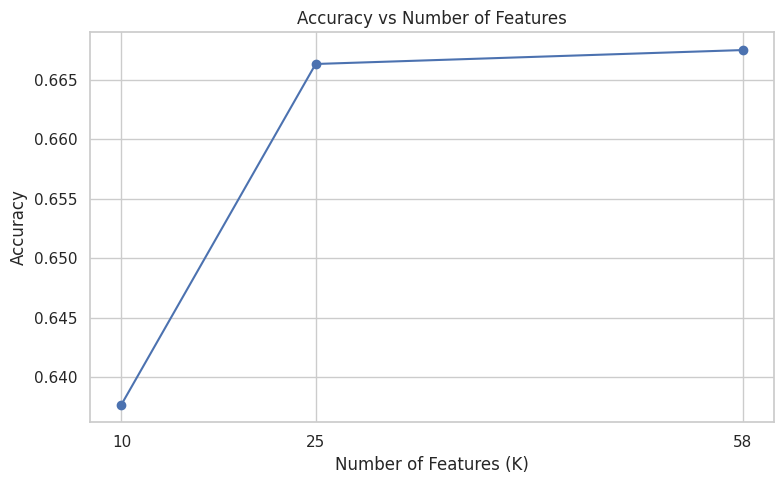

In [74]:
k_values = [10, 25, 58]

accuracies = []

for k in k_values:

    selected_features = mi.head(k).index.tolist()

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    model.fit(
        X_train[selected_features],
        y_train
    )

    predictions = model.predict(
        X_test[selected_features]
    )

    acc = accuracy_score(y_test, predictions)

    accuracies.append(acc)

    print(f"K = {k}, Accuracy = {acc:.4f}")


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracies,
    marker="o"
)

plt.title("Accuracy vs Number of Features")
plt.xlabel("Number of Features (K)")
plt.ylabel("Accuracy")

plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

\**📝 Bonus answer:**

The accuracy increased as the number of features increased. With 10 features, the accuracy was 63.77%. With 25 features, it improved to 66.63%, and with 58 features, it reached 66.75%. The best result was achieved using all 58 features. However, the improvement from 25 to 58 features was very small. This shows that using more features does not always lead to a significant improvement in model performance.

## Final Reflection (5 pts)

Write 5–8 sentences: what was the hardest part, what surprised you in the data, what would you add to the dataset or the model to predict popularity better, and one ethical concern about predicting which news will "go viral".

*Your answer:*

---

## Grading (100 pts + 10 bonus)

| Part | Points |
|---|---|
| 1. Load & inspect | 10 |
| 2. Explore the target | 10 |
| 3. Cleaning & target | 15 |
| 4. Factors influencing popularity | 20 |
| 5. Train/Test split | 5 |
| 6. Feature selection | 10 |
| 7. Baseline + Random Forest | 10 |
| 8. Evaluation | 10 |
| 9. Logistic Regression & comparison | 15 |
| Final reflection | 10 |
| **Total** | **115** (capped at 100, plus bonus) |

*Written answers are graded on understanding, not length. Clean, readable plots (titles, labels) and a notebook that runs top to bottom are part of every section's grade.*

## Submission
1. **Runtime → Restart and run all**, and confirm there are no errors.
2. **File → Download → Download .ipynb**, named `FirstName_LastName_NewsPopularity.ipynb`.
3. Submit the file (or a shared Colab link with **Viewer access**) by the deadline.

The hardest part of this project was selecting the important features and training the machine learning models. I was surprised that Random Forest achieved better accuracy than Logistic Regression. I also learned that not all features have the same effect on news popularity. To improve the predictions, I would add more information about audience interests and social media activity. I would also try different machine learning models to improve the results. One ethical concern is that predicting popular news may encourage publishers to focus on viral content instead of important and reliable news. This could spread misleading information and affect readers.